# Activité Pratique N°4 — Architecture Transformer
## Partie 1 — Étape 4 : Modèle Transformer

**IA Générative Multi Modale — 5IAD G1, EMSI** · Étudiant : BENHAYOUN SADAFI Mohamed

Créer, entraîner et tester un Transformer qui prédit la valeur suivante d'une séquence de 10 éléments.

> 🔁 **Code refait** — le dataset est de l'étape 1 (notebook `1 - Dataset serie temporelle`).
> Chaque notebook est indépendant : il recrée ce dont il a besoin au lieu de dépendre d'un autre notebook.

In [1]:
import json
import random
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn


def fixer_graine(graine=42):
    random.seed(graine)
    np.random.seed(graine)
    torch.manual_seed(graine)


fixer_graine()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch", torch.__version__, "| appareil :", device,
      f"({torch.cuda.get_device_name(0)})" if device.type == "cuda" else "")

PyTorch 2.14.1+cu126 | appareil : cuda (NVIDIA GeForce MX450)


In [2]:
# 200 valeurs de sin(x) entre 0 et 20, fenêtres de 10 valeurs -> valeur suivante
x = torch.linspace(0, 20, 200)
s = torch.sin(x)
longueur_sequence = 10

X = torch.stack([s[i:i + longueur_sequence] for i in range(len(s) - longueur_sequence)]).unsqueeze(-1)  # (190, 10, 1)
Y = torch.stack([s[i + longueur_sequence] for i in range(len(s) - longueur_sequence)]).unsqueeze(-1)    # (190, 1)

X_train, Y_train = X[:150], Y[:150]
X_test, Y_test = X[150:], Y[150:]
print("Train :", tuple(X_train.shape), tuple(Y_train.shape), "| Test :", tuple(X_test.shape), tuple(Y_test.shape))

Train : (150, 10, 1) (150, 1) | Test : (40, 10, 1) (40, 1)


> 🔁 **Code refait** — fonctions d'entraînement et d'affichage, identiques à celles des notebooks RNN et LSTM.

In [3]:
FICHIER_RESULTATS = Path("resultats_partie1.json")   # partagé avec le notebook 4 pour la comparaison


def nb_parametres(modele):
    return sum(p.numel() for p in modele.parameters())


def entrainer_serie(modele, epochs=300, lr=0.01):
    # Même protocole pour les trois modèles : Adam, MSE, 300 époques, un seul lot.
    fixer_graine()
    modele = modele.to(device)
    optimiseur = torch.optim.Adam(modele.parameters(), lr=lr)
    critere = nn.MSELoss()
    Xtr, Ytr = X_train.to(device), Y_train.to(device)
    pertes = []
    for epoch in range(epochs):
        modele.train()
        perte = critere(modele(Xtr), Ytr)
        optimiseur.zero_grad()
        perte.backward()
        optimiseur.step()
        pertes.append(perte.item())
        if (epoch + 1) % 50 == 0:
            print(f"Époque {epoch + 1:3d} | MSE entraînement : {perte.item():.6f}")
    modele.eval()
    with torch.no_grad():
        predictions = modele(X_test.to(device)).cpu()
    mse_test = critere(predictions, Y_test).item()
    print(f"\nMSE test : {mse_test:.6f}")
    print(f"Premier exemple de test : réel = {Y_test[0].item():.4f} | prédit = {predictions[0].item():.4f}")
    return predictions, mse_test, pertes


def tracer_predictions(predictions, nom):
    plt.figure(figsize=(12, 4))
    plt.plot(Y_test.numpy().ravel(), label="Valeurs réelles", color="tab:blue", linewidth=2)
    plt.plot(predictions.numpy().ravel(), label=f"Prédictions du {nom}", color="tab:red", linestyle="--", linewidth=2)
    plt.title(f"{nom} : valeurs réelles et prédictions sur le test")
    plt.xlabel("Indice de l'exemple de test")
    plt.ylabel("Valeur")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()


def sauvegarder_resultat(nom, mse_test, modele, pertes, predictions):
    resultats = json.loads(FICHIER_RESULTATS.read_text(encoding="utf-8")) if FICHIER_RESULTATS.exists() else {}
    resultats[nom] = {"mse_test": mse_test, "parametres": nb_parametres(modele), "pertes": pertes,
                      "predictions": predictions.numpy().ravel().tolist()}
    FICHIER_RESULTATS.write_text(json.dumps(resultats), encoding="utf-8")
    print(f"Résultats du {nom} enregistrés dans {FICHIER_RESULTATS}")

### Le mécanisme d'attention (rappel du cours)

Chaque position calcule une requête $Q$, une clé $K$ et une valeur $V$ :

$$\mathrm{Attention}(Q,K,V)=\mathrm{softmax}\!\left(\frac{QK^\top}{\sqrt{d_k}}\right)V$$

Petit calcul à la main avec 2 tokens, comme sur la diapositive du cours :

In [4]:
fixer_graine()
d_model, d_k = 4, 4
X_tokens = torch.randn(2, d_model)                    # 2 tokens (embeddings x1, x2)
Wq, Wk, Wv = (torch.randn(d_model, d_k) for _ in range(3))
Q, K, V = X_tokens @ Wq, X_tokens @ Wk, X_tokens @ Wv
scores = Q @ K.T / d_k ** 0.5                         # produits scalaires q_i . k_j / sqrt(d_k)
poids = torch.softmax(scores, dim=-1)                 # chaque ligne somme à 1
Z = poids @ V                                         # combinaison pondérée des valeurs
print("Scores QK^T/sqrt(dk) :\n", scores.round(decimals=2))
print("Poids d'attention (softmax) :\n", poids.round(decimals=2))
print("Sortie Z = SM . V :", tuple(Z.shape))

Scores QK^T/sqrt(dk) :
 tensor([[-0.2100, -1.2500],
        [-0.4900, -1.1900]])
Poids d'attention (softmax) :
 tensor([[0.7400, 0.2600],
        [0.6700, 0.3300]])
Sortie Z = SM . V : (2, 4)


### Encodage de position

L'attention ne connaît pas l'ordre. Le Transformer original utilise des sinus/cosinus :
$PE_{(pos,2i)} = \sin(pos/10000^{2i/d})$, $PE_{(pos,2i+1)} = \cos(pos/10000^{2i/d})$.
GPT et BERT (et notre modèle ci-dessous) utilisent plutôt des **vecteurs de position appris** (`nn.Embedding`).

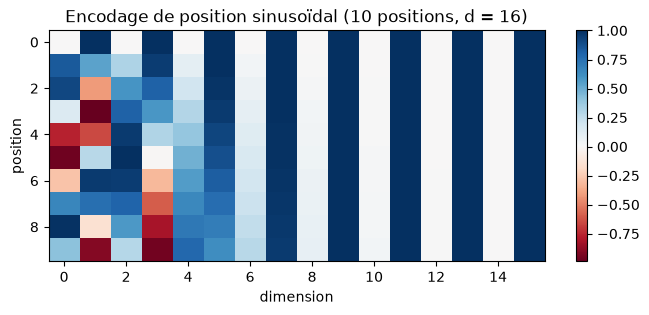

In [5]:
positions = torch.arange(10).unsqueeze(1)
i = torch.arange(0, 16, 2)
pe = torch.zeros(10, 16)
pe[:, 0::2] = torch.sin(positions / 10000 ** (i / 16))
pe[:, 1::2] = torch.cos(positions / 10000 ** (i / 16))
plt.figure(figsize=(8, 3))
plt.imshow(pe, cmap="RdBu", aspect="auto")
plt.xlabel("dimension")
plt.ylabel("position")
plt.title("Encodage de position sinusoïdal (10 positions, d = 16)")
plt.colorbar()
plt.show()

### Architecture de notre modèle (schéma du tableau)

```
Entrées x1…xn ──► Projection linéaire 1→16 ──┐
Indices 0…n-1 ──► Positional Embedding ──────(+)
                                              │
            Multi-Head Self-Attention (2 têtes, dimension 16)
                                              │
            Addition (résiduelle) + Norm Layer
                                              │
            Feed Forward 16→32→16 avec ReLU
                                              │
            Addition (résiduelle) + Norm Layer
                                              │
            Garder la dernière représentation [:, -1, :] ──► Linear(16→1) ──► ŷ
```
Aucun masque causal n'est nécessaire : les 10 valeurs d'entrée sont toutes connues et la cible n'est jamais donnée en entrée.

In [6]:
class ModeleTransformer(nn.Module):
    def __init__(self, longueur_max=10, d_model=16, nhead=2, dim_ff=32):
        super().__init__()
        self.projection = nn.Linear(1, d_model)
        self.positions = nn.Embedding(longueur_max, d_model)
        couche = nn.TransformerEncoderLayer(d_model=d_model, nhead=nhead, dim_feedforward=dim_ff,
                                            dropout=0.0, activation="relu", batch_first=True)
        self.encodeur = nn.TransformerEncoder(couche, num_layers=1, enable_nested_tensor=False)
        self.sortie = nn.Linear(d_model, 1)

    def forward(self, x):                                   # (B, 10, 1)
        indices = torch.arange(x.size(1), device=x.device)  # [0, 1, …, 9]
        z = self.projection(x) + self.positions(indices)    # (B, 10, 16)
        z = self.encodeur(z)                                # (B, 10, 16)
        return self.sortie(z[:, -1, :])                     # dernière position -> (B, 1)


fixer_graine()
transformer = ModeleTransformer(longueur_max=longueur_sequence)
print(transformer)
print("Paramètres :", nb_parametres(transformer))

ModeleTransformer(
  (projection): Linear(in_features=1, out_features=16, bias=True)
  (positions): Embedding(10, 16)
  (encodeur): TransformerEncoder(
    (layers): ModuleList(
      (0): TransformerEncoderLayer(
        (self_attn): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=16, out_features=16, bias=True)
        )
        (linear1): Linear(in_features=16, out_features=32, bias=True)
        (dropout): Dropout(p=0.0, inplace=False)
        (linear2): Linear(in_features=32, out_features=16, bias=True)
        (norm1): LayerNorm((16,), eps=1e-05, elementwise_affine=True, bias=True)
        (norm2): LayerNorm((16,), eps=1e-05, elementwise_affine=True, bias=True)
        (dropout1): Dropout(p=0.0, inplace=False)
        (dropout2): Dropout(p=0.0, inplace=False)
      )
    )
  )
  (sortie): Linear(in_features=16, out_features=1, bias=True)
)
Paramètres : 2433


### Entraînement et test

Époque  50 | MSE entraînement : 0.001504


Époque 100 | MSE entraînement : 0.000110


Époque 150 | MSE entraînement : 0.000026


Époque 200 | MSE entraînement : 0.000012


Époque 250 | MSE entraînement : 0.000007


Époque 300 | MSE entraînement : 0.000004

MSE test : 0.000006
Premier exemple de test : réel = -0.3639 | prédit = -0.3662


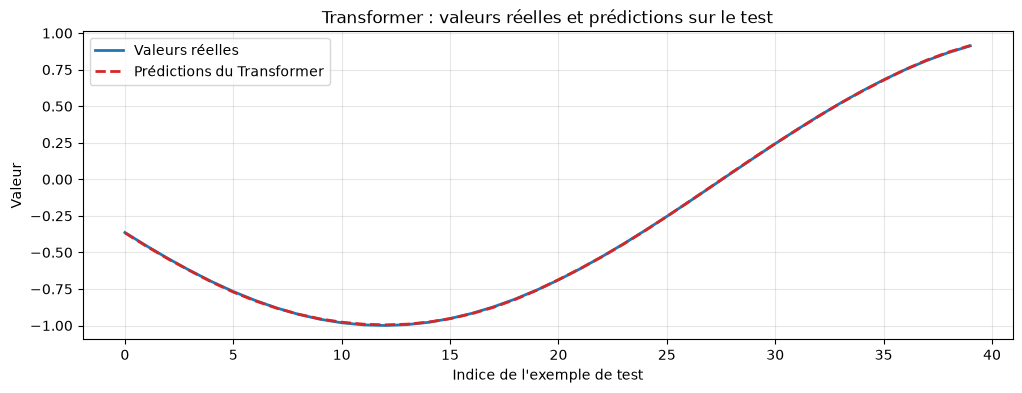

Résultats du Transformer enregistrés dans resultats_partie1.json


In [7]:
pred_tr, mse_tr, pertes_tr = entrainer_serie(transformer)
tracer_predictions(pred_tr, "Transformer")
sauvegarder_resultat("Transformer", mse_tr, transformer, pertes_tr, pred_tr)

### Comparaison RNN / LSTM / Transformer

Les résultats des notebooks 2 et 3 sont relus depuis `resultats_partie1.json` (exécuter les notebooks 2 et 3 avant celui-ci).

Modèle         MSE test  Paramètres
RNN            0.000028         321
LSTM           0.000003        1233
Transformer    0.000006        2433


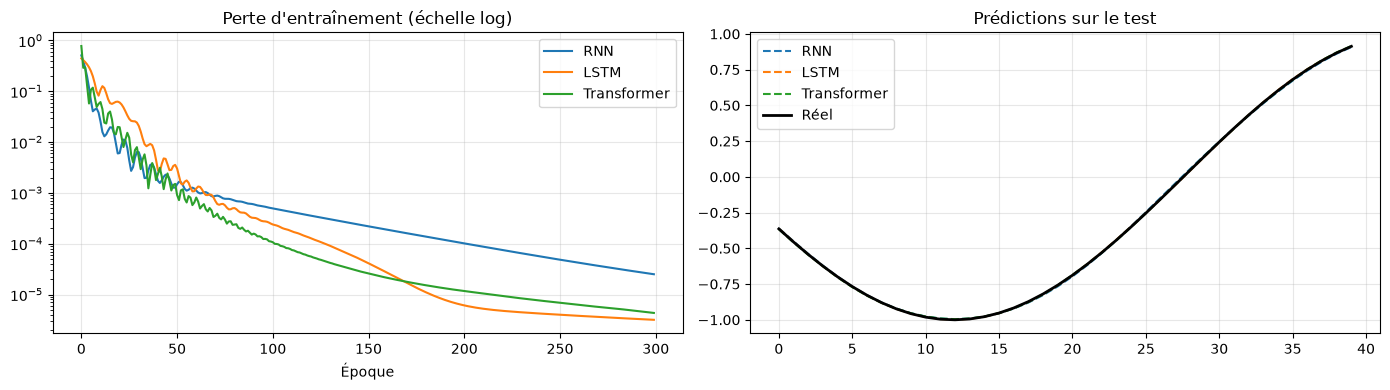

In [8]:
resultats = json.loads(FICHIER_RESULTATS.read_text(encoding="utf-8"))
print(f"{'Modèle':12s} {'MSE test':>10s} {'Paramètres':>11s}")
for nom, r in resultats.items():
    print(f"{nom:12s} {r['mse_test']:10.6f} {r['parametres']:11d}")

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for nom, r in resultats.items():
    axes[0].plot(r["pertes"], label=nom)
    axes[1].plot(r["predictions"], linestyle="--", label=nom)
axes[0].set_yscale("log")
axes[0].set_title("Perte d'entraînement (échelle log)")
axes[0].set_xlabel("Époque")
axes[1].plot(Y_test.numpy().ravel(), color="black", linewidth=2, label="Réel")
axes[1].set_title("Prédictions sur le test")
for ax in axes:
    ax.legend()
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Lecture des résultats.** Les trois modèles apprennent la sinusoïde : la tâche est simple (fonction périodique, régulière, sans bruit), donc les erreurs de test restent faibles pour tous.
Les écarts de MSE dépendent ici de la taille des modèles, de l'initialisation et des 300 époques fixées : sur une série aussi courte, ils ne permettent pas de conclure qu'une architecture est meilleure en général.

| RNN / LSTM | Transformer |
|---|---|
| Traitement pas à pas, état transmis d'un instant au suivant | Toutes les positions mises en relation directement par l'attention |
| Ordre intégré au traitement | Ordre fourni par l'encodage de position |
| Difficile à paralléliser | Parallélisable (coût quadratique en la longueur) |